<a href="https://colab.research.google.com/github/padmashree07-sudo/Graph-Neural-Network-Based-Network-Attack-Path-Detection-Framework/blob/main/GNN_Attack_Path.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Graph Neural Network-Based Network Attack Path Detection Framework
Capstone Project | Google Colab Implementation

In [14]:
!pip install torch_geometric

In [15]:
import networkx as nx
import numpy as np
import pandas as pd
import random, time
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from collections import Counter
from torch_geometric.nn import GCNConv, SAGEConv, GATConv
from torch_geometric.data import Data
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# MODULE 1: Network Asset Discovery
Builds the enterprise network graph. Each device is a node (type, CVSS score, open ports) and each allowed connection is a directed edge.


In [16]:
random.seed(42)
np.random.seed(42)
G = nx.DiGraph()

def add(prefix, count, ntype, cvss, ports, critical=0):
    ids = []
    for i in range(count):
        n = G.number_of_nodes()
        G.add_node(n, name=f"{prefix}{i+1}", type=ntype,
                   cvss=round(random.uniform(*cvss), 1),
                   ports=random.randint(*ports), critical=critical)
        ids.append(n)
    return ids

internet = add("Internet", 1, "internet", (0, 0), (0, 0))
firewall = add("FW", 1, "firewall", (2, 5), (2, 4))
web      = add("Web", 4, "dmz", (5, 9.8), (3, 8))
mail     = add("Mail", 2, "dmz", (4, 8), (3, 6))
app      = add("App", 6, "server", (3, 8), (3, 7))
db       = add("DB", 3, "database", (2, 7), (2, 4), critical=1)
users    = add("PC", 30, "user", (4, 9), (2, 6))
admin    = add("Admin", 3, "admin", (2, 6), (2, 5))
iot      = add("IoT", 10, "iot", (6, 9.8), (1, 4))

def connect(src_list, dst_list, k):
    for s in src_list:
        for d in random.sample(dst_list, min(k, len(dst_list))):
            G.add_edge(s, d)

# directed edges = allowed connections
connect(internet, firewall, 1)
connect(firewall, web + mail, 4)
connect(web, app, 2)
connect(mail, users, 5)
connect(users, app, 1)
connect(users, users, 2)
connect(iot, users, 1)
connect(app, db, 1)
connect(admin, db, 2)
connect(admin, app, 2)
for u in users:
    if random.random() < 0.3:
        G.add_edge(u, random.choice(admin))
    if random.random() < 0.3:
        G.add_edge(u, random.choice(iot))
G.remove_edges_from(list(nx.selfloop_edges(G)))

ENTRY = internet[0]
targets = db
print("Devices:", G.number_of_nodes(), "| Connections:", G.number_of_edges())

Devices: 60 | Connections: 158


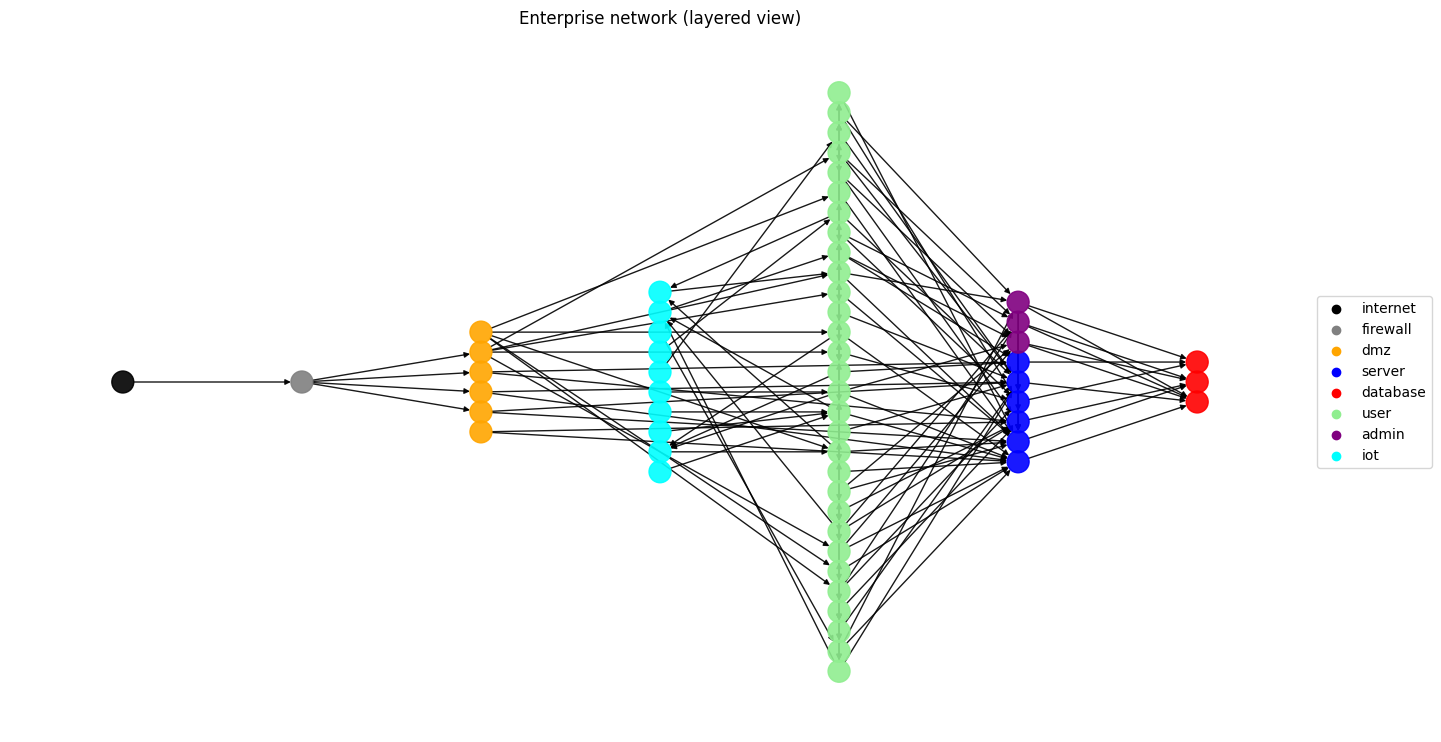

In [23]:
layer = {"internet":0, "firewall":1, "dmz":2, "iot":3, "user":4,
         "server":5, "admin":5, "database":6}
for n in G.nodes:
    G.nodes[n]["layer"] = layer[G.nodes[n]["type"]]

pos = nx.multipartite_layout(G, subset_key="layer")
colors = [color_map[G.nodes[n]["type"]] for n in G.nodes]

plt.figure(figsize=(13, 7))
nx.draw(G, pos, node_color=colors, node_size=250, arrows=True, arrowsize=8, alpha=0.9)
for t, c in color_map.items():
    plt.scatter([], [], c=c, label=t)
plt.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.title("Enterprise network (layered view)")
plt.show()

# MODULE 2: GNN Attack-Path Analysis
Simulates attacks to create risk labels, trains GCN, GraphSAGE and GAT models, compares them with an MLP and a CVSS rule, and explains the predictions.


In [18]:
def simulate(G, n_sims=2000):
    counts = np.zeros(G.number_of_nodes())
    for _ in range(n_sims):
        hit = {ENTRY}
        stack = [ENTRY]
        while stack:
            cur = stack.pop()
            for nb in G.successors(cur):
                if nb not in hit and random.random() < G.nodes[nb]["cvss"] / 10:
                    hit.add(nb)
                    stack.append(nb)
        for n in hit:
            counts[n] += 1
    return counts / n_sims

t0 = time.time()
risk_true = simulate(G)
sim_time = time.time() - t0

# label 1 = in the more-often-compromised half of the network
labels = (risk_true > np.median(risk_true)).astype(int)
print("Simulation time:", round(sim_time, 2), "sec")
print("High-risk nodes:", labels.sum(), "of", len(labels))

Simulation time: 0.14 sec
High-risk nodes: 30 of 60


In [19]:
types = list(color_map.keys())
x = torch.tensor([
    [G.nodes[n]["cvss"] / 10, G.nodes[n]["ports"] / 10, G.nodes[n]["critical"]]
    + [1 if G.nodes[n]["type"] == t else 0 for t in types]
    for n in G.nodes], dtype=torch.float)

edge_index = torch.tensor(list(G.edges), dtype=torch.long).t().contiguous()
y = torch.tensor(labels, dtype=torch.long)
data = Data(x=x, edge_index=edge_index, y=y)

def make_masks(seed):
    g = torch.Generator().manual_seed(seed)
    perm = torch.randperm(data.num_nodes, generator=g)
    cut = int(0.6 * data.num_nodes)
    train = torch.zeros(data.num_nodes, dtype=torch.bool)
    test = torch.zeros(data.num_nodes, dtype=torch.bool)
    train[perm[:cut]] = True
    test[perm[cut:]] = True
    return train, test

print(data)

Data(x=[60, 11], edge_index=[2, 158], y=[60])


In [20]:
class Net(torch.nn.Module):
    def __init__(self, kind, in_dim):
        super().__init__()
        self.kind = kind
        if kind == "MLP":
            self.l1 = torch.nn.Linear(in_dim, 32)
            self.l2 = torch.nn.Linear(32, 2)
        else:
            Conv = {"GCN": GCNConv, "GraphSAGE": SAGEConv, "GAT": GATConv}[kind]
            self.l1 = Conv(in_dim, 32)
            self.l2 = Conv(32, 2)

    def forward(self, x, edge_index):
        if self.kind == "MLP":
            return self.l2(F.relu(self.l1(x)))
        return self.l2(F.relu(self.l1(x, edge_index)), edge_index)

def train_model(kind, train_mask, test_mask, epochs=200):
    model = Net(kind, data.num_features)
    opt = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=5e-4)
    for _ in range(epochs):
        model.train()
        opt.zero_grad()
        out = model(data.x, data.edge_index)
        loss = F.cross_entropy(out[train_mask], data.y[train_mask])
        loss.backward()
        opt.step()
    model.eval()
    with torch.no_grad():
        pred = model(data.x, data.edge_index).argmax(1)
    yt = data.y[test_mask].numpy()
    yp = pred[test_mask].numpy()
    scores = [accuracy_score(yt, yp),
              precision_score(yt, yp, zero_division=0),
              recall_score(yt, yp, zero_division=0),
              f1_score(yt, yp, zero_division=0)]
    return model, scores

In [21]:
rows = []

# Baseline: "patch anything with CVSS >= 7" rule
base = []
for seed in range(5):
    _, test_mask = make_masks(seed)
    yt = data.y[test_mask].numpy()
    yp = np.array([1 if G.nodes[n]["cvss"] >= 7 else 0 for n in G.nodes])[test_mask.numpy()]
    base.append([accuracy_score(yt, yp), precision_score(yt, yp, zero_division=0),
                 recall_score(yt, yp, zero_division=0), f1_score(yt, yp, zero_division=0)])
rows.append(["CVSS rule only"] + list(np.mean(base, axis=0)))

for kind in ["MLP", "GCN", "GraphSAGE", "GAT"]:
    all_scores = []
    for seed in range(5):
        torch.manual_seed(seed)
        tr, te = make_masks(seed)
        _, s = train_model(kind, tr, te)
        all_scores.append(s)
    rows.append([kind] + list(np.mean(all_scores, axis=0)))

results = pd.DataFrame(rows, columns=["Model", "Accuracy", "Precision", "Recall", "F1"]).round(3)
print(results.to_string(index=False))

         Model  Accuracy  Precision  Recall    F1
CVSS rule only     0.475      0.387   0.369 0.370
           MLP     0.558      0.543   0.478 0.492
           GCN     0.850      0.821   0.854 0.832
     GraphSAGE     0.708      0.676   0.717 0.687
           GAT     0.817      0.789   0.815 0.797


In [24]:
best_kind = "GCN"
torch.manual_seed(0)
tr, te = make_masks(0)
model, _ = train_model(best_kind, tr, te)

t0 = time.time()
with torch.no_grad():
    risk = F.softmax(model(data.x, data.edge_index), dim=1)[:, 1].numpy()
gnn_time = time.time() - t0

for n in G.nodes:
    G.nodes[n]["risk"] = float(risk[n])

print(f"Simulation: {sim_time:.3f}s | GNN prediction: {gnn_time:.4f}s")
top = sorted(G.nodes, key=lambda n: G.nodes[n]["risk"], reverse=True)[:5]
for n in top:
    print(G.nodes[n]["name"], "risk =", round(G.nodes[n]["risk"], 2))

Simulation: 0.140s | GNN prediction: 0.0023s
Web3 risk = 1.0
FW1 risk = 1.0
Web4 risk = 1.0
Web2 risk = 1.0
Mail1 risk = 1.0


In [25]:
from torch_geometric.explain import Explainer, GNNExplainer

explainer = Explainer(
    model=model,
    algorithm=GNNExplainer(epochs=100),
    explanation_type="model",
    node_mask_type="attributes",
    edge_mask_type="object",
    model_config=dict(mode="multiclass_classification",
                      task_level="node", return_type="raw"))

target = max((n for n in G.nodes if n != ENTRY), key=lambda n: G.nodes[n]["risk"])
exp = explainer(data.x, data.edge_index, index=target)

names = ["cvss", "ports", "critical"] + types
imp = exp.node_mask[target].detach().numpy()
print("Explaining node:", G.nodes[target]["name"])
for name, v in sorted(zip(names, imp), key=lambda a: -a[1])[:4]:
    print(" feature", name, round(float(v), 3))

top_edges = exp.edge_mask.topk(5).indices
print("Most influential connections:")
for i in top_edges:
    s, d = data.edge_index[0][i].item(), data.edge_index[1][i].item()
    print(" ", G.nodes[s]["name"], "->", G.nodes[d]["name"])

Explaining node: Web3
 feature ports 0.718
 feature dmz 0.281
 feature cvss 0.262
 feature critical 0.0
Most influential connections:
  Internet1 -> FW1
  FW1 -> Web3
  PC21 -> Admin3
  PC22 -> Admin1
  PC22 -> App6


# MODULE 3: Critical Path Mitigation
Ranks attack paths by risk, finds choke points, and measures how much total risk drops after fixing them.


In [26]:
paths = []
for t in targets:
    for p in nx.all_simple_paths(G, ENTRY, t, cutoff=6):
        score = sum(G.nodes[n]["risk"] for n in p) / len(p)
        paths.append((score, p))

paths.sort(reverse=True)
print("Total attack paths:", len(paths))
print("Top 5 paths:")
for s, p in paths[:5]:
    print(round(s, 2), " -> ".join(G.nodes[n]["name"] for n in p))

Total attack paths: 45
Top 5 paths:
0.97 Internet1 -> FW1 -> Web3 -> App1 -> DB3
0.97 Internet1 -> FW1 -> Web3 -> App5 -> DB3
0.97 Internet1 -> FW1 -> Web2 -> App5 -> DB3
0.95 Internet1 -> FW1 -> Mail1 -> PC7 -> App1 -> DB3
0.95 Internet1 -> FW1 -> Web2 -> App2 -> DB1


In [27]:
count = Counter()
for s, p in paths:
    for n in p[1:-1]:
        count[n] += s

print("Top choke points:")
for n, c in count.most_common(5):
    print(G.nodes[n]["name"], round(c, 1))

Top choke points:
FW1 38.5
Mail1 33.0
PC7 9.8
Admin2 8.6
PC27 8.5


          Strategy          Nodes fixed  Risk reduced %
Choke-point method [Mail1, PC7, Admin2]            85.8
     Greedy method  [Mail1, Web3, Web2]            95.8
Highest CVSS first   [Web3, IoT4, IoT2]             5.0
Random (avg of 20)               varies            18.5


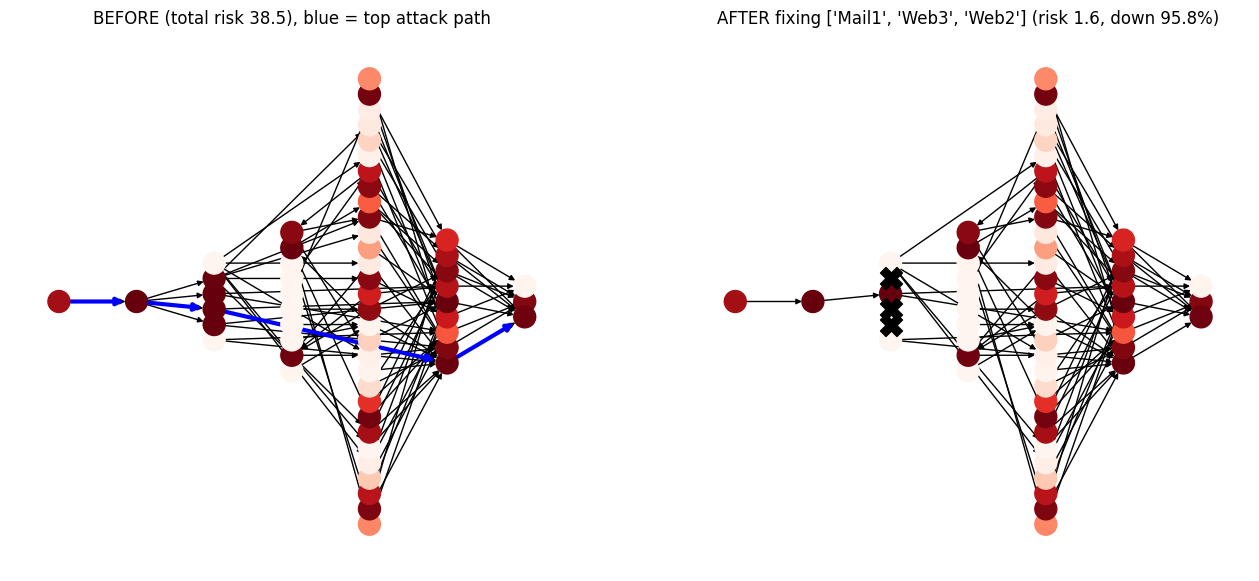

In [36]:
# ---------- Step 13 (new): compare fixing strategies ----------
def total_risk(graph):
    total = 0
    for t in targets:
        if t in graph and nx.has_path(graph, ENTRY, t):
            for p in nx.all_simple_paths(graph, ENTRY, t, cutoff=6):
                total += sum(graph.nodes[n]["risk"] for n in p) / len(p)
    return total

before = total_risk(G)

def reduction(nodes_to_remove):
    H = G.copy()
    H.remove_nodes_from(nodes_to_remove)
    return (before - total_risk(H)) / before * 100

names = lambda s: [G.nodes[n]["name"] for n in s]

# only these can be fixed (not internet, firewall or databases)
candidates = [n for n in G.nodes
              if G.nodes[n]["type"] not in ("internet", "firewall", "database")]

ours = [n for n, _ in count.most_common() if n in candidates][:3]

greedy_nodes = []
for _ in range(3):
    best = max((n for n in candidates if n not in greedy_nodes),
               key=lambda n: reduction(greedy_nodes + [n]))
    greedy_nodes.append(best)

by_cvss = sorted(candidates, key=lambda n: G.nodes[n]["cvss"], reverse=True)[:3]
rand_avg = np.mean([reduction(random.sample(candidates, 3)) for _ in range(20)])

table = pd.DataFrame({
    "Strategy": ["Choke-point method", "Greedy method", "Highest CVSS first", "Random (avg of 20)"],
    "Nodes fixed": [names(ours), names(greedy_nodes), names(by_cvss), "varies"],
    "Risk reduced %": [round(reduction(ours), 1), round(reduction(greedy_nodes), 1),
                       round(reduction(by_cvss), 1), round(rand_avg, 1)]})
print(table.to_string(index=False))

# ---------- Step 14 (new): before vs after, using the greedy fix ----------
fix = greedy_nodes
H = G.copy()
H.remove_nodes_from(fix)
after = total_risk(H)
top_path = paths[0][1]
top_edges = list(zip(top_path, top_path[1:]))

fig, ax = plt.subplots(1, 2, figsize=(16, 7))
nx.draw(G, pos, ax=ax[0], node_color=[G.nodes[n]["risk"] for n in G.nodes],
        cmap=plt.cm.Reds, vmin=0, vmax=1, node_size=250, arrowsize=8)
nx.draw_networkx_edges(G, pos, edgelist=top_edges, edge_color="blue", width=3, ax=ax[0])
ax[0].set_title(f"BEFORE (total risk {before:.1f}), blue = top attack path")

nx.draw(H, pos, ax=ax[1], node_color=[H.nodes[n]["risk"] for n in H.nodes],
        cmap=plt.cm.Reds, vmin=0, vmax=1, node_size=250, arrowsize=8)
nx.draw_networkx_nodes(G, pos, nodelist=fix, node_color="black",
                       node_shape="X", node_size=250, ax=ax[1])
ax[1].set_title(f"AFTER fixing {names(fix)} (risk {after:.1f}, down {reduction(fix):.1f}%)")
plt.show()